## 2.1. Project Setup

This section defines the project paths for the Sentinel-2 imagery, the original Feng PV mask, the aligned mask, and the output directory for the training tiles.

In [120]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import rioxarray
from rasterio.enums import Resampling
import geoai

# Define project paths
BASE_DIR = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR = BASE_DIR / "data"

raster_path = DATA_DIR / "raw" / "raster" / "sentinel2" / "talatan_2020_best.tif"
original_mask_path = DATA_DIR / "raw" / "raster" / "feng" / "feng.tif"
aligned_mask_path = DATA_DIR / "processed" / "feng_aligned.tif"
output_dir = DATA_DIR / "processed" / "tiles"

print("Paths loaded successfully!")

Paths loaded successfully!


## 2.2. Check Coordinate Reference Systems

The coordinate reference systems (CRS) of the Sentinel-2 image and the original Feng mask are checked before processing to identify potential spatial alignment issues.

In [121]:
with rasterio.open(raster_path) as src:
    print(f"Sentinel-2 image (Talatan): -> CRS: {src.crs}")

with rasterio.open(original_mask_path) as src:
    print(f"Raster mask (Feng): -> CRS: {src.crs}")

Sentinel-2 image (Talatan): -> CRS: EPSG:32647
Raster mask (Feng): -> CRS: EPSG:4326


## 2.3. Align the PV Mask with Sentinel-2

The original Feng mask is reprojected to match the spatial reference system, pixel grid, and resolution of the Sentinel-2 image. Nearest-neighbor resampling is used to preserve the original class values of the binary mask (0 = non-PV, 1 = PV).

The aligned mask is saved for the subsequent tiling process.

In [141]:
print("Adapting feng.tif to the Sentinel-2 image (CRS & grid)...")

sentinel_2 = rioxarray.open_rasterio(raster_path)
feng = rioxarray.open_rasterio(original_mask_path)

# Reproject using Nearest Neighbor (crucial for class values 0 and 1)
aligned_feng = feng.rio.reproject_match(sentinel_2, resampling=Resampling.nearest)

# Save the aligned raster mask
aligned_feng.rio.to_raster(aligned_mask_path)
print(f"Aligned mask saved successfully to:\n{aligned_mask_path}")

Adapting feng.tif to the Sentinel-2 image (CRS & grid)...
Aligned mask saved successfully to:
/Users/fabianott/Desktop/sds320/project/data/processed/feng_aligned.tif


## 2.4. Generate Training Tiles

The Sentinel-2 image and the aligned PV mask are divided into smaller tiles using GeoAI. A tile size of 512 × 512 pixels and a stride of 384 pixels are used, resulting in an overlap of 128 pixels between neighbouring tiles.

The tile coordinates and feature statistics are retained for subsequent inspection. An overview image is requested to visualize the spatial distribution of the generated tiles.

In [ ]:
print("Starting automated tiling with geoai...")

tiles = geoai.export_geotiff_tiles(
    in_raster=str(raster_path),
    out_folder=str(output_dir),
    in_class_data=str(aligned_mask_path),
    tile_size=512,
    stride=384,
    buffer_radius=0,
    create_overview=True,
    quiet=False,
)

print(f"\nDone! All training tiles were created under:\n{output_dir}")

Starting automated tiling with geoai...


Generating tiles:   0%|          | 0/143 [00:00<?, ?it/s]

Failed to create overview image: cannot access local variable 'rasterio' where it is not associated with a value



Done! All training tiles were created under:
/Users/fabianott/Desktop/sds320/project/data/processed/tiles


## 2.5. Display Overview Image

Displaying overview image...


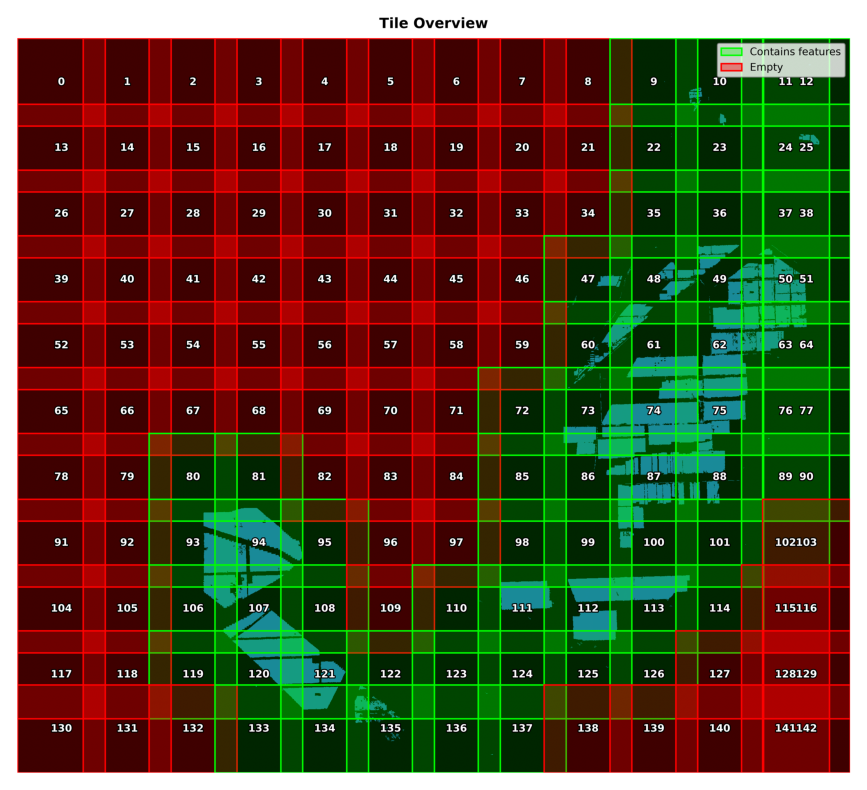

In [138]:
overview_path = output_dir / "overview.png" 

if overview_path.exists():
    print("Displaying overview image...")
    geoai.view_image(str(overview_path), figsize=(18, 10))
else:
    print("No overview image found in the folder.")

## 2.6. Inspect Randomly Selected Training Tiles

Twenty tiles are randomly selected for visual inspection, using a fixed random seed to ensure reproducibility. The Sentinel-2 RGB imagery is displayed together with the corresponding Feng PV mask.

This visual inspection helps assess whether the imagery and labels are spatially aligned and whether the PV class is represented correctly in the training data.

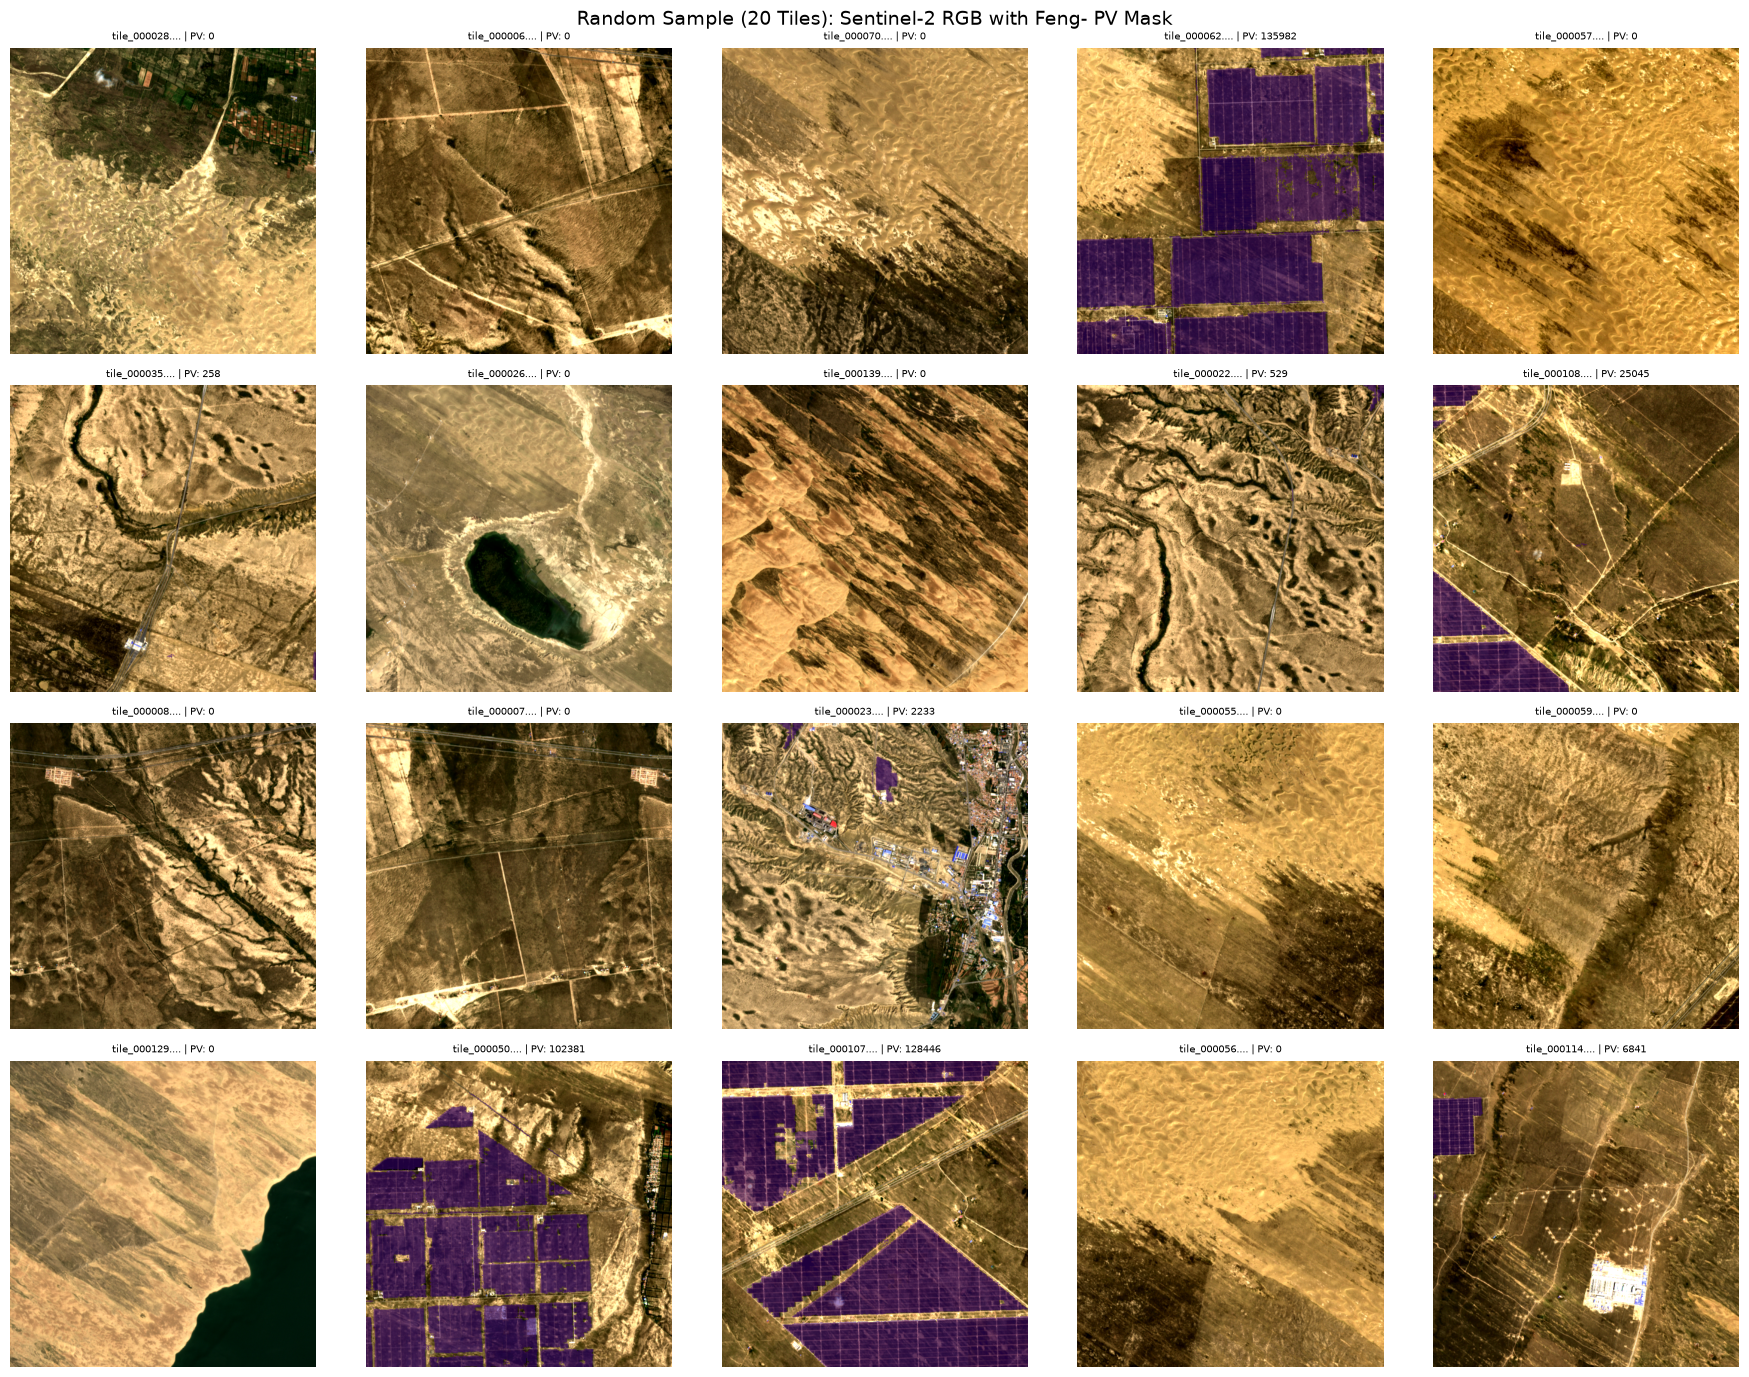

In [137]:
random.seed(42)  # For reproducibility
image_dir = output_dir / "images"
mask_dir = output_dir / "labels"
image_files = sorted(list(image_dir.glob("*.tif")))

if image_files:
    num_to_show = min(20, len(image_files))
    selected_images = random.sample(image_files, num_to_show)
    
    rows, cols = 4, 5
    fig, axes = plt.subplots(rows, cols, figsize=(18, 14))
    axes = axes.flatten()
    
    for i, ax in enumerate(axes):
        if i < num_to_show:
            img_path = selected_images[i]
            mask_path = mask_dir / img_path.name
            
            if mask_path.exists():
                with rasterio.open(img_path) as src_img:
                    count = src_img.count
                    r, g, b = (3, 2, 1) if count >= 4 else (min(3, count), min(2, count), min(1, count))
                    img = src_img.read([r, g, b])
                    img = np.moveaxis(img, 0, -1)
                    
                    if np.any(img > 0):
                        p2, p98 = np.percentile(img[img > 0], (2, 98))
                        img = np.clip((img - p2) / (p98 - p2 + 1e-5), 0, 1)
                
                with rasterio.open(mask_path) as src_mask:
                    mask = src_mask.read(1)
                
                ax.imshow(img)
                mask_display = np.ma.masked_where(mask != 1, mask)
                ax.imshow(mask_display, cmap='Purples', vmin=0, vmax=1, alpha=0.5)
                
                pv_count = np.sum(mask == 1)
                ax.set_title(f"{img_path.name[:12]}... | PV: {pv_count}", fontsize=7)
            else:
                ax.set_title("Mask missing", fontsize=7, color='red')
        ax.axis('off')
        
    plt.suptitle("Random Sample (20 Tiles): Sentinel-2 RGB with Feng- PV Mask", fontsize=14, y=0.98)
    plt.tight_layout()
    plt.show()
else:
    print(f"No tiles found in directory: {image_dir}")